# ACF/PACF dan Kandidat Model SARIMA

Langkah 3. Dari hasil langkah 2, keempat deret (asli, d=1, D=1, d=1 & D=1) lolos uji ADF, tetapi pola musiman mingguan masih sangat kuat. Di notebook ini ACF/PACF dipakai untuk memilih orde (p, q, P, Q) dan menyusun daftar kandidat model SARIMA(p,d,q)(P,D,Q)$_7$.

**Catatan:** notebook ini hanya *mengidentifikasi* kandidat. Estimasi parameter dan pemilihan model (AIC/BIC, RMSE) dilakukan setelah pembagian train/test (langkah 4) agar tidak terjadi kebocoran data.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})
S = 7          # periode musiman (harian, pola mingguan)
NLAGS = 5 * S  # tampilkan 5 siklus musiman

## 1. Muat data

In [2]:
df = pd.read_excel("../data/jk_pasien.xlsx")
df["tanggal"] = pd.to_datetime(df["tanggal"])
y = df.sort_values("tanggal").set_index("tanggal")["jk"].astype(float).asfreq("D")

deret = {
    "Asli": y,
    "d = 1": y.diff(1),
    f"D = 1 (lag {S})": y.diff(S),
    f"d = 1, D = 1 (lag {S})": y.diff(1).diff(S),
}
len(y), y.isna().sum()

(1382, 0)

## 2. ACF & PACF tiap deret

Pita biru = batas signifikansi 95%. Garis vertikal putus-putus menandai kelipatan lag musiman (7, 14, 21, ...).

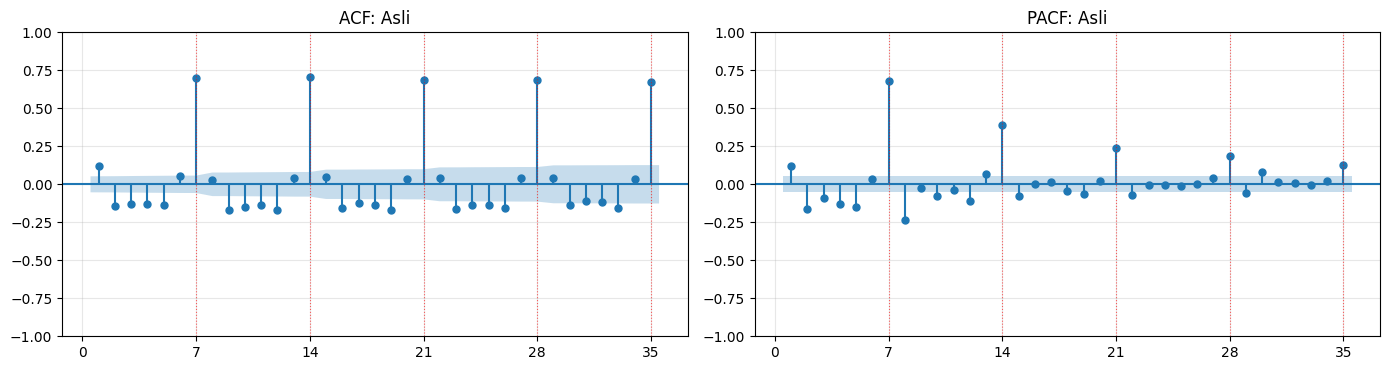

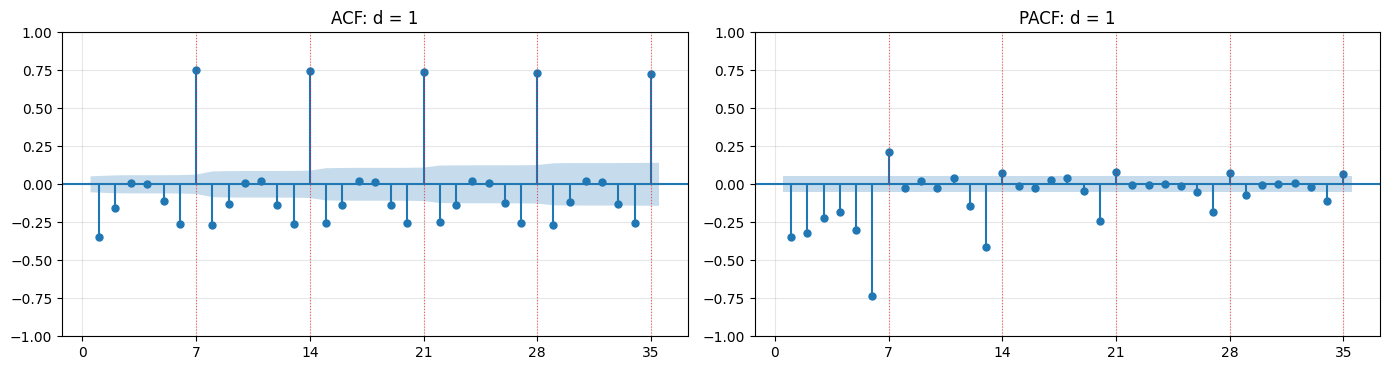

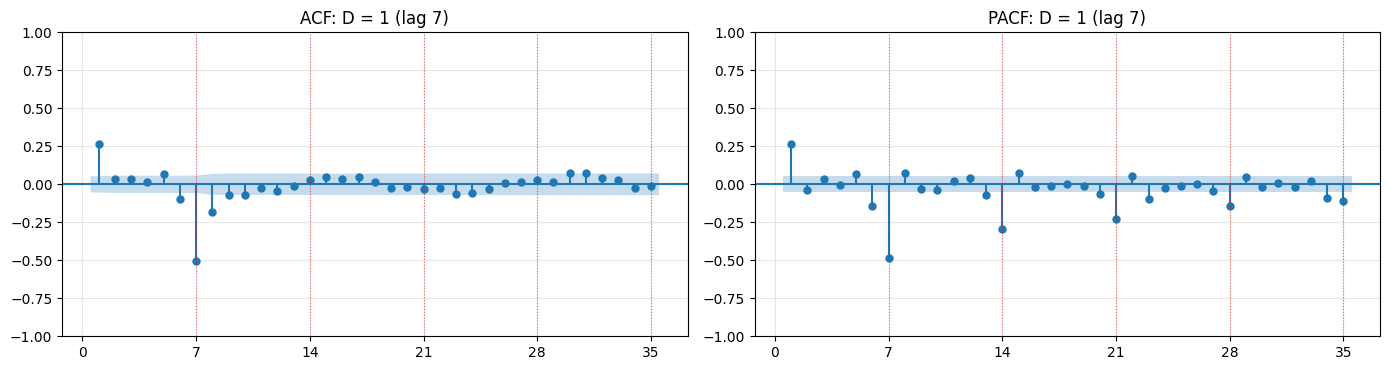

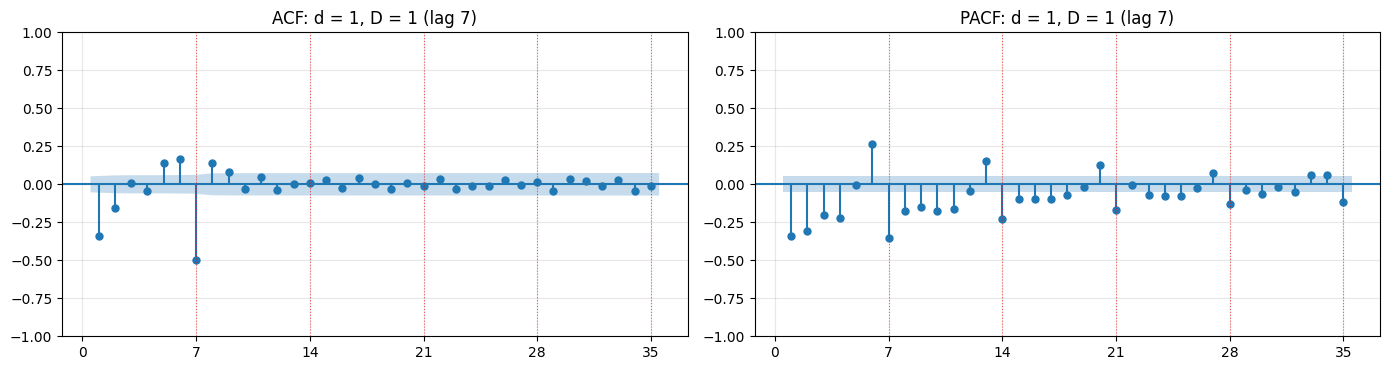

In [3]:
def plot_acf_pacf(s, judul, nlags=NLAGS):
    x = s.dropna()
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
    plot_acf(x, lags=nlags, ax=axes[0], zero=False, title=f"ACF: {judul}")
    plot_pacf(x, lags=nlags, ax=axes[1], zero=False, method="ywm", title=f"PACF: {judul}")
    for ax in axes:
        for k in range(S, nlags + 1, S):
            ax.axvline(k, color="r", ls=":", lw=.8, alpha=.6)
        ax.set_xticks(range(0, nlags + 1, S))
    plt.tight_layout()
    plt.show()

for nama, s in deret.items():
    plot_acf_pacf(s, nama)

## 3. Lag signifikan (tabel ringkas)

In [4]:
def lag_signifikan(s, nlags=NLAGS):
    x = s.dropna()
    batas = 1.96 / np.sqrt(len(x))
    a, p = acf(x, nlags=nlags), pacf(x, nlags=nlags, method="ywm")
    ambil = lambda v: [k for k in range(1, nlags + 1) if abs(v[k]) > batas]
    return batas, ambil(a), ambil(p)

baris = []
for nama, s in deret.items():
    b, la, lp = lag_signifikan(s)
    baris.append({"Deret": nama, "Batas ±": round(b, 3),
                  "Lag ACF signifikan": la[:12], "Lag PACF signifikan": lp[:12]})
pd.DataFrame(baris).set_index("Deret")

,Batas ±,Lag ACF signifikan,Lag PACF signifikan
Deret,,,
Asli,0.053,"[1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14]","[1, 2, 3, 4, 5, 7, 8, 10, 12, 13, 14, 15]"
d = 1,0.053,"[1, 2, 5, 6, 7, 8, 9, 12, 13, 14, 15, 16]","[1, 2, 3, 4, 5, 6, 7, 12, 13, 14, 20, 21]"
D = 1 (lag 7),0.053,"[1, 5, 6, 7, 8, 9, 10, 23, 24, 30, 31]","[1, 5, 6, 7, 8, 13, 14, 15, 20, 21, 23, 28]"
"d = 1, D = 1 (lag 7)",0.053,"[1, 2, 5, 6, 7, 8, 9]","[1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 13, 14]"


## 4. Interpretasi

**Deret asli.** ACF tinggi dan berulang di lag 7, 14, 21, 28 (≈0,7) dan PACF besar di lag 7 (0,68). Ini pola musiman mingguan yang kuat, jadi differencing musiman (D = 1) diperlukan.

**d = 1 saja.** ACF di lag 7, 14, 21, 28 tetap ≈0,75, jadi musiman belum hilang. Lag 1 menjadi negatif (−0,35), tanda awal over-differencing. Tidak dipilih sebagai satu-satunya differencing.

**D = 1 (lag 7).**
- Bagian musiman: ACF terpotong di lag 7 (−0,50) dan tidak signifikan di lag 14 dan 21, sedangkan PACF meluruh di lag 7, 14, 21 (−0,49, −0,30, −0,23) → **Q = 1, P = 0** (SMA(1)).
- Bagian non-musiman: ACF dan PACF sama-sama signifikan di lag 1 (0,27) → **p = 1 atau q = 1**.
- Deret sudah stasioner (ADF & KPSS sepakat) → **d = 0** cukup.

**d = 1, D = 1.** ACF signifikan di lag 1 (−0,34), 2 (−0,16), dan 7 (−0,50), PACF meluruh perlahan → pola MA: **q = 1–2, Q = 1**. Bentuk ini mirip *airline model*.

Kesimpulan: keluarga model yang masuk akal adalah SARIMA dengan **D = 1, Q = 1, P = 0**, dengan variasi orde non-musiman dan d ∈ {0, 1}.

## 5. Kandidat model

In [5]:
kandidat = pd.DataFrame([
    ("M1", (0, 0, 1), (0, 1, 1), "MA(1) non-musiman + SMA(1); paling sederhana"),
    ("M2", (1, 0, 0), (0, 1, 1), "AR(1) non-musiman + SMA(1)"),
    ("M3", (1, 0, 1), (0, 1, 1), "ARMA(1,1) + SMA(1); lag 1 ACF & PACF sama-sama signifikan"),
    ("M4", (0, 1, 1), (0, 1, 1), "Airline model; ACF d=1,D=1 terpotong di lag 1 dan 7"),
    ("M5", (0, 1, 2), (0, 1, 1), "Seperti M4, ditambah MA(2) (ACF lag 2 = −0,16)"),
    ("M6", (1, 1, 1), (0, 1, 1), "ARIMA(1,1,1) + SMA(1); variasi dengan AR"),
    ("M7", (1, 0, 1), (1, 1, 1), "Seperti M3, ditambah SAR(1) sebagai pembanding"),
], columns=["Kode", "(p,d,q)", "(P,D,Q)", "Alasan"])
kandidat["Model"] = kandidat.apply(lambda r: f"SARIMA{r['(p,d,q)']}{r['(P,D,Q)']}[{S}]", axis=1)
kandidat.set_index("Kode")[["Model", "Alasan"]]

,Model,Alasan
Kode,,
M1,"SARIMA(0, 0, 1)(0, 1, 1)[7]",MA(1) non-musiman + SMA(1); paling sederhana
M2,"SARIMA(1, 0, 0)(0, 1, 1)[7]",AR(1) non-musiman + SMA(1)
M3,"SARIMA(1, 0, 1)(0, 1, 1)[7]","ARMA(1,1) + SMA(1); lag 1 ACF & PACF sama-sama..."
M4,"SARIMA(0, 1, 1)(0, 1, 1)[7]","Airline model; ACF d=1,D=1 terpotong di lag 1 ..."
M5,"SARIMA(0, 1, 2)(0, 1, 1)[7]","Seperti M4, ditambah MA(2) (ACF lag 2 = −0,16)"
M6,"SARIMA(1, 1, 1)(0, 1, 1)[7]","ARIMA(1,1,1) + SMA(1); variasi dengan AR"
M7,"SARIMA(1, 0, 1)(1, 1, 1)[7]","Seperti M3, ditambah SAR(1) sebagai pembanding"


## 6. Langkah berikutnya

1. Bagi data menjadi train/test secara kronologis (langkah 4).
2. Estimasi ketujuh kandidat pada **data train**, bandingkan AIC/BIC, lalu cek residual (Ljung-Box, ACF residual).
3. Evaluasi model terbaik pada data test dan bandingkan dengan LSTM (langkah 5-6).

Catatan: kandidat dengan parameter tidak signifikan atau residual masih berautokorelasi dapat dibuang pada tahap ini.